# 02 — Análisis de la réplica

**Etapa 3 (Arie).** ¿Qué tan replicable es Too et al. (2019) y qué aporta cada componente de CBPSO-MIWS?

1. Réplica vs. artículo (Wilcoxon de una muestra)
2. ¿CBPSO-MIWS supera a BPSO, como afirma el artículo?
3. Glass y la columna ID
4. Óptimo exacto: ¿qué tan seguido se encuentra la mejor solución posible?
5. Sensibilidad al número de especies `ns`
6. Ablación: co-evolución × inercia múltiple
7. Conclusiones de replicabilidad

Datos: `results/runs.csv` (30 corridas × 7 bases × 6 configuraciones, etapa 2),
`results/etapa3/runs.csv` (sensibilidad y ablación), `results/optimo_exacto.csv`,
`results/tasa_acierto.csv` y `data/paper_results.csv` (Tablas 3 y 5 del artículo).
Este notebook no vuelve a correr experimentos.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from bfs.replication import compare_with_paper, load_paper_results, side_by_side
from bfs.stats import compare_all

RESULTS = Path("../results")
FIGS = RESULTS / "figures"
FIGS.mkdir(exist_ok=True)

runs = pd.read_csv(RESULTS / "runs.csv")
etapa3 = pd.read_csv(RESULTS / "etapa3" / "runs.csv")
paper = load_paper_results()
optimos = pd.read_csv(RESULTS / "optimo_exacto.csv")
tasa = pd.read_csv(RESULTS / "tasa_acierto.csv")

NOMBRES = {
    "breast_cancer_wisconsin": "Wisconsin", "glass": "Glass", "glass_id": "Glass + ID",
    "ionosphere": "Ionosphere", "libras": "Libras", "breast_cancer_coimbra": "Coimbra",
    "lung_cancer": "Lung Cancer",
}
ORDEN_BASES = ["breast_cancer_wisconsin", "breast_cancer_coimbra", "glass", "glass_id",
               "ionosphere", "lung_cancer", "libras"]
pd.set_option("display.width", 200)

def guardar(fig, nombre):
    fig.savefig(FIGS / f"etapa3_{nombre}.png", dpi=300, bbox_inches="tight")

## 1. Réplica vs. artículo

El artículo solo publica el **promedio** de sus 20 corridas. Comparamos nuestras 30 corridas
contra ese valor con una **prueba de Wilcoxon de una muestra** (H0: la mediana de
*réplica − artículo* es 0), con corrección de Holm por método y métrica.

In [2]:
side_by_side(runs, "accuracy").rename(index=NOMBRES).loc[[NOMBRES[b] for b in ORDEN_BASES]]

,BPSO artículo,BPSO réplica,CBPSO-MIWS artículo,CBPSO-MIWS réplica
dataset,,,,
Wisconsin,98.96,97.95 ± 1.02,99.14,97.98 ± 0.99
Coimbra,86.09,87.92 ± 4.81,90.87,88.47 ± 4.47
Glass,94.65,79.07 ± 4.57,98.37,79.61 ± 4.35
Glass + ID,94.65,98.91 ± 1.33,98.37,98.91 ± 1.33
Ionosphere,88.00,94.13 ± 2.13,91.36,94.55 ± 2.45
Lung Cancer,82.50,94.29 ± 8.05,89.17,93.33 ± 7.25
Libras,79.44,82.45 ± 5.32,82.01,82.27 ± 5.05


In [3]:
comp = compare_with_paper(runs)
tabla = (comp[comp["metric"] == "accuracy"]
         [["method", "dataset", "ours_mean", "ours_median", "ours_std", "paper", "diff", "p_holm", "resultado"]]
         .round(3))
tabla["dataset"] = tabla["dataset"].map(NOMBRES)
tabla

,method,dataset,ours_mean,ours_median,ours_std,paper,diff,p_holm,resultado
0,cbpso_miws,Coimbra,88.472,87.500,4.469,90.87,-2.398,0.041,menor
1,cbpso_miws,Wisconsin,97.976,97.857,0.994,99.14,-1.164,0.000,menor
2,cbpso_miws,Glass,79.612,79.070,4.348,98.37,-18.758,0.000,menor
3,cbpso_miws,Glass + ID,98.915,100.000,1.329,98.37,0.545,0.027,mayor
4,cbpso_miws,Ionosphere,94.554,94.366,2.446,91.36,3.194,0.000,mayor
5,cbpso_miws,Libras,82.269,83.333,5.050,82.01,0.259,0.797,igual
6,cbpso_miws,Lung Cancer,93.333,100.000,7.249,89.17,4.163,0.027,mayor
28,bpso,Coimbra,87.917,87.500,4.813,86.09,1.827,0.063,igual
29,bpso,Wisconsin,97.952,97.857,1.023,98.96,-1.008,0.000,menor
30,bpso,Glass,79.070,79.070,4.570,94.65,-15.580,0.000,menor


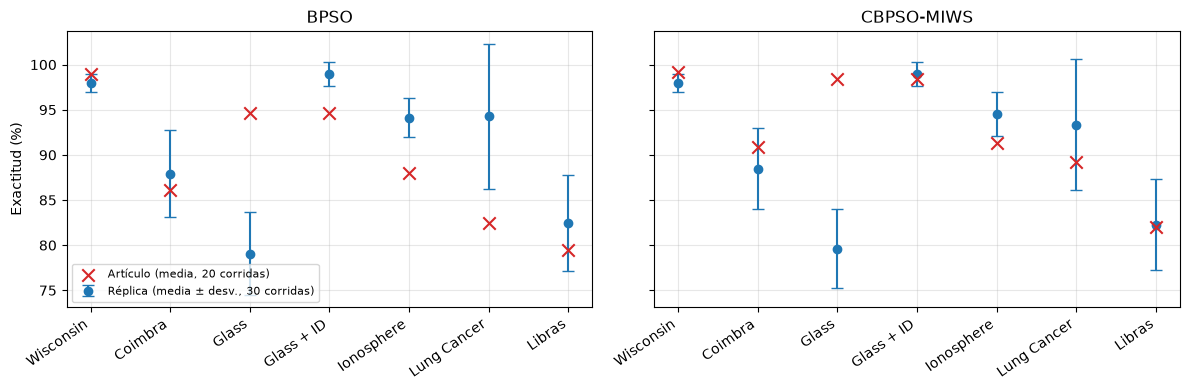

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
x = np.arange(len(ORDEN_BASES))
for ax, (method, titulo) in zip(axes, [("bpso", "BPSO"), ("cbpso_miws", "CBPSO-MIWS")]):
    g = runs[runs["method"] == method].groupby("dataset")["accuracy"]
    media = g.mean().reindex(ORDEN_BASES)
    desv = g.std().reindex(ORDEN_BASES)
    art = [paper[(paper["dataset"] == ("glass" if b == "glass_id" else b))
                 & (paper["method"] == titulo)]["accuracy"].iloc[0] for b in ORDEN_BASES]
    ax.errorbar(x, media, yerr=desv, fmt="o", color="tab:blue", capsize=4, label="Réplica (media ± desv., 30 corridas)")
    ax.scatter(x, art, marker="x", s=80, color="tab:red", zorder=3, label="Artículo (media, 20 corridas)")
    ax.set_xticks(x, [NOMBRES[b] for b in ORDEN_BASES], rotation=35, ha="right")
    ax.set_title(titulo)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Exactitud (%)")
axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout()
guardar(fig, "replica_vs_articulo")
plt.show()

**Lectura.** La réplica de CBPSO-MIWS no difiere del artículo en Libras y queda **por encima** en
Ionosphere, Lung Cancer y Glass + ID; queda **por debajo** en Wisconsin, Coimbra y, sobre todo,
Glass sin ID (sección 3). En cambio, nuestro **BPSO** supera claramente al BPSO reportado
(p. ej. Lung Cancer 94.3 % vs. 82.5 %, Ionosphere 94.1 % vs. 88.0 %): la línea base del artículo
parece más débil de lo que da una implementación estándar.

## 2. ¿CBPSO-MIWS supera a BPSO?

El artículo (Tabla 4, prueba t) afirma que CBPSO-MIWS es significativamente mejor que BPSO en
exactitud en 8 de 10 bases. Comparamos con nuestro Wilcoxon pareado (30 corridas, Holm).

In [5]:
articulo_t = {  # Tabla 4 del artículo, columna BPSO (* = CBPSO-MIWS significativamente mejor)
    "breast_cancer_wisconsin": "0.364 (no sig.)", "glass": "0.0016 *", "ionosphere": "1e-05 *",
    "libras": "0.0002 *", "breast_cancer_coimbra": "0.0001 *", "lung_cancer": "0.0020 *",
}
w = compare_all(runs, reference="cbpso_miws", challengers=["bpso"], metrics=("accuracy", "best_fitness"))
tabla2 = (w.pivot(index="dataset", columns="metric", values="resultado_holm")
            .rename(columns={"accuracy": "réplica: exactitud", "best_fitness": "réplica: fitness"}))
tabla2.insert(0, "artículo: p (prueba t)", pd.Series(articulo_t))
tabla2.rename(index=NOMBRES).loc[[NOMBRES[b] for b in ORDEN_BASES]].fillna("—")

metric,artículo: p (prueba t),réplica: exactitud,réplica: fitness
dataset,,,
Wisconsin,0.364 (no sig.),empate,empate
Coimbra,0.0001 *,empate,empate
Glass,0.0016 *,empate,empate
Glass + ID,—,empate,empate
Ionosphere,1e-05 *,empate,empate
Lung Cancer,0.0020 *,empate,empate
Libras,0.0002 *,empate,empate


**Lectura.** En nuestra réplica **no hay diferencia significativa** entre CBPSO-MIWS y BPSO en
ninguna base, ni en exactitud ni en fitness. La ventaja que reporta el artículo no se reproduce;
la explicación más probable es la de la sección 1: su BPSO de referencia rinde por debajo de un BPSO estándar.
(Además, la sección 4 muestra que CBPSO-MIWS **sí** encuentra el óptimo más seguido que BPSO en las
bases pequeñas: la diferencia existe, pero es pequeña y no siempre se nota en la exactitud.)

## 3. Glass y la columna ID

La Tabla 1 del artículo reporta Glass con **10** variables, pero el archivo de UCI tiene 9 variables
químicas + un **ID** consecutivo. Las filas vienen ordenadas por clase, así que el ID revela la etiqueta.

In [6]:
g = runs[runs["dataset"].isin(["glass", "glass_id"]) & runs["method"].isin(["bpso", "cbpso_miws"])].copy()
g["usa_ID"] = (g["dataset"] == "glass_id") & g["selected"].astype(str).str.split(";").apply(lambda s: "0" in s)
resumen_glass = g.groupby(["dataset", "method"]).agg(
    exactitud=("accuracy", "mean"), variables=("n_features", "mean"), usa_ID=("usa_ID", "mean")).round(2)
resumen_glass["artículo"] = [94.65, 98.37, 94.65, 98.37]
resumen_glass

exactitud  variables  usa_ID  artículo
dataset  method                                            
glass    bpso            79.07       4.07     0.0     94.65
         cbpso_miws      79.61       4.33     0.0     98.37
glass_id bpso            98.91       1.37     1.0     94.65
         cbpso_miws      98.91       1.50     1.0     98.37

**Lectura.** Con el ID, ambos métodos lo seleccionan en el **100 %** de las corridas y alcanzan ~99 %,
igual o más que lo reportado (98.37 %); sin el ID la exactitud cae a ~80 %. Es la evidencia más fuerte
de que el artículo **incluyó el ID como variable** (fuga de la etiqueta), lo que invalida el resultado
de Glass como medida del algoritmo.

## 4. Óptimo exacto

En las bases con 9–10 variables hay solo 511–1,023 subconjuntos: los evaluamos **todos** en cada
una de las 30 particiones para conocer el **óptimo global real** y medir en qué porcentaje de corridas
lo encontró cada método. El artículo no puede medir esto.

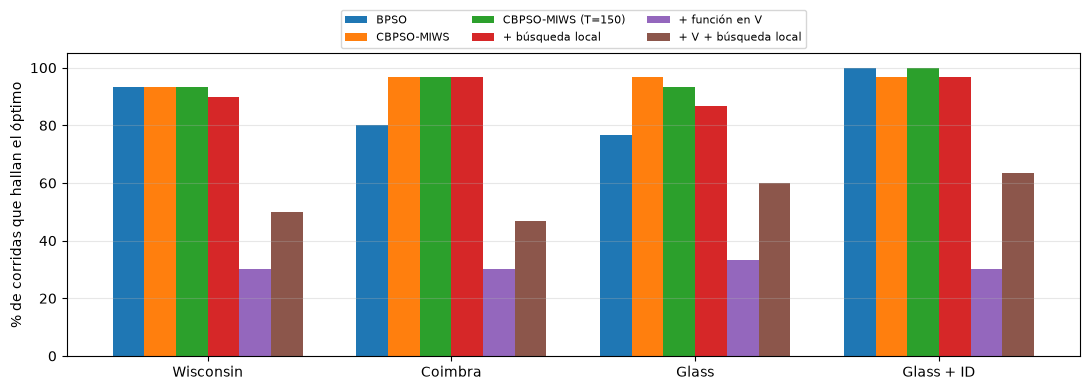

method,BPSO,CBPSO-MIWS,CBPSO-MIWS (T=150),+ búsqueda local,+ función en V,+ V + búsqueda local
dataset,,,,,,
Wisconsin,93.3,93.3,93.3,90.0,30.0,50.0
Coimbra,80.0,96.7,96.7,96.7,30.0,46.7
Glass,76.7,96.7,93.3,86.7,33.3,60.0
Glass + ID,100.0,96.7,100.0,96.7,30.0,63.3


In [7]:
orden_m = ["bpso", "cbpso_miws", "cbpso_miws_T150", "cbpso_miws_ls", "cbpso_miws_v", "cbpso_miws_v_ls"]
etiquetas = {"bpso": "BPSO", "cbpso_miws": "CBPSO-MIWS", "cbpso_miws_T150": "CBPSO-MIWS (T=150)",
             "cbpso_miws_ls": "+ búsqueda local", "cbpso_miws_v": "+ función en V",
             "cbpso_miws_v_ls": "+ V + búsqueda local"}
pequenas = ["breast_cancer_wisconsin", "breast_cancer_coimbra", "glass", "glass_id"]
piv = tasa.pivot(index="dataset", columns="method", values="hit_rate").loc[pequenas, orden_m]

fig, ax = plt.subplots(figsize=(11, 4))
ancho = 0.13
for i, m in enumerate(orden_m):
    ax.bar(np.arange(len(pequenas)) + (i - 2.5) * ancho, piv[m], ancho, label=etiquetas[m])
ax.set_xticks(np.arange(len(pequenas)), [NOMBRES[b] for b in pequenas])
ax.set_ylabel("% de corridas que hallan el óptimo")
ax.set_ylim(0, 105)
ax.grid(axis="y", alpha=0.3)
ax.legend(fontsize=8, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0))
plt.tight_layout()
guardar(fig, "optimo_exacto")
plt.show()

piv.rename(index=NOMBRES, columns=etiquetas).round(1)

In [8]:
print("Corridas cuyo fitness guardado no se reprodujo en esta máquina (empates de KNN):",
      int(tasa["n_differs"].sum()), "de", int(tasa["n"].sum()))
optimos.groupby("dataset")[["opt_accuracy", "opt_n_features", "n_optimal"]].mean().rename(index=NOMBRES).round(2)

Corridas cuyo fitness guardado no se reprodujo en esta máquina (empates de KNN): 0 de 720


,opt_accuracy,opt_n_features,n_optimal
dataset,,,
Coimbra,88.61,4.00,1.50
Wisconsin,97.98,4.20,1.60
Glass,79.61,4.30,1.17
Glass + ID,98.91,1.37,1.03


**Lectura.** CBPSO-MIWS halla el óptimo en ~97 % de las corridas en Coimbra y Glass, contra ~77–80 % de
BPSO: aquí la co-evolución **sí** ayuda. La función en V lo halla solo en ~30 %, lo que confirma con la
respuesta exacta que la mejora 1 empeora el algoritmo. La exactitud media del óptimo (p. ej. Glass ≈ 80 %)
es el **techo** real de este protocolo: ningún método puede reportar 98 % en Glass sin el ID.

## 5. Sensibilidad al número de especies `ns`

El artículo dice que `ns` = 3 y 4 dieron los mejores resultados, pero no muestra los datos.
Corrimos `ns` = 1…5 (30 corridas) en las tres bases con margen de mejora (34–90 variables).

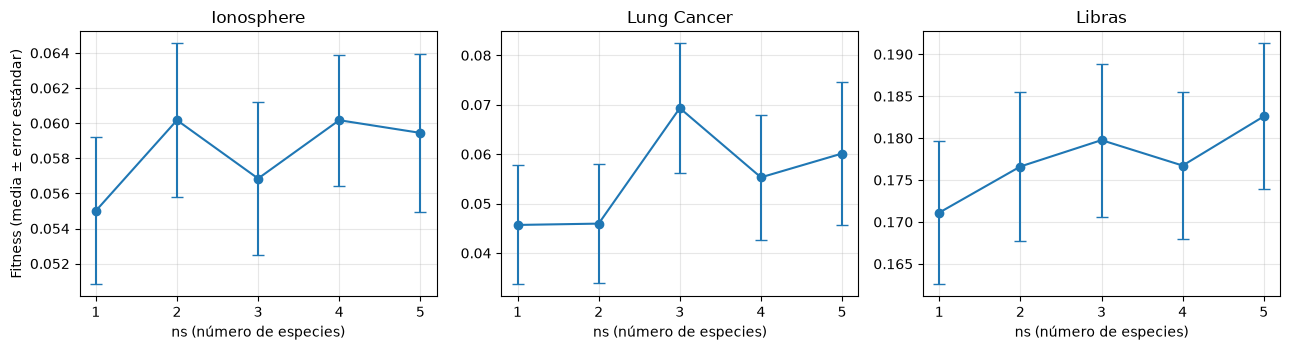

dataset,Ionosphere,Libras,Lung Cancer
method,,,
cbpso_ns1,empate,empate,empate
cbpso_ns2,empate,empate,empate
cbpso_ns4,empate,empate,empate
cbpso_ns5,empate,empate,empate


In [9]:
NS = {"cbpso_ns1": 1, "cbpso_ns2": 2, "cbpso_miws": 3, "cbpso_ns4": 4, "cbpso_ns5": 5}
grandes = ["ionosphere", "lung_cancer", "libras"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, base in zip(axes, grandes):
    sub = etapa3[(etapa3["dataset"] == base) & etapa3["method"].isin(NS)]
    # Media ± error estándar (en Lung Cancer el fitness es casi binario y la mediana/RIC no informan)
    g = sub.groupby("method")["best_fitness"]
    q = pd.DataFrame({"media": g.mean(), "ee": g.std() / np.sqrt(g.count())}).rename(index=NS).sort_index()
    ax.errorbar(q.index, q["media"], yerr=q["ee"], fmt="o-", capsize=4)
    ax.set(title=NOMBRES[base], xlabel="ns (número de especies)", xticks=list(NS.values()))
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Fitness (media ± error estándar)")
plt.tight_layout()
guardar(fig, "sensibilidad_ns")
plt.show()

w_ns = compare_all(etapa3, reference="cbpso_miws", challengers=[m for m in NS if m != "cbpso_miws"],
                   metrics=("best_fitness",))
w_ns.pivot(index="method", columns="dataset", values="resultado_holm").rename(columns=NOMBRES)

**Lectura.** Ninguna elección de `ns` es significativamente distinta de `ns` = 3 en estas bases
(Wilcoxon pareado + Holm, referencia = `cbpso_miws`): con una población de solo 10 partículas,
el número de especies no es un factor decisivo. No encontramos evidencia de que 3 o 4 sean mejores;
si acaso, la tendencia numérica favorece a `ns` = 1 (sin co-evolución) en las tres bases, aunque sin significancia.

## 6. Ablación: co-evolución × inercia múltiple

| | Inercia múltiple (4 esquemas) | Un solo esquema |
|---|---|---|
| **Co-evolución (ns = 3)** | `cbpso_miws` | `cbpso_iws1` … `cbpso_iws4` |
| **Sin co-evolución (ns = 1)** | `cbpso_ns1` | `bpso` (equivale a IWS 1) |

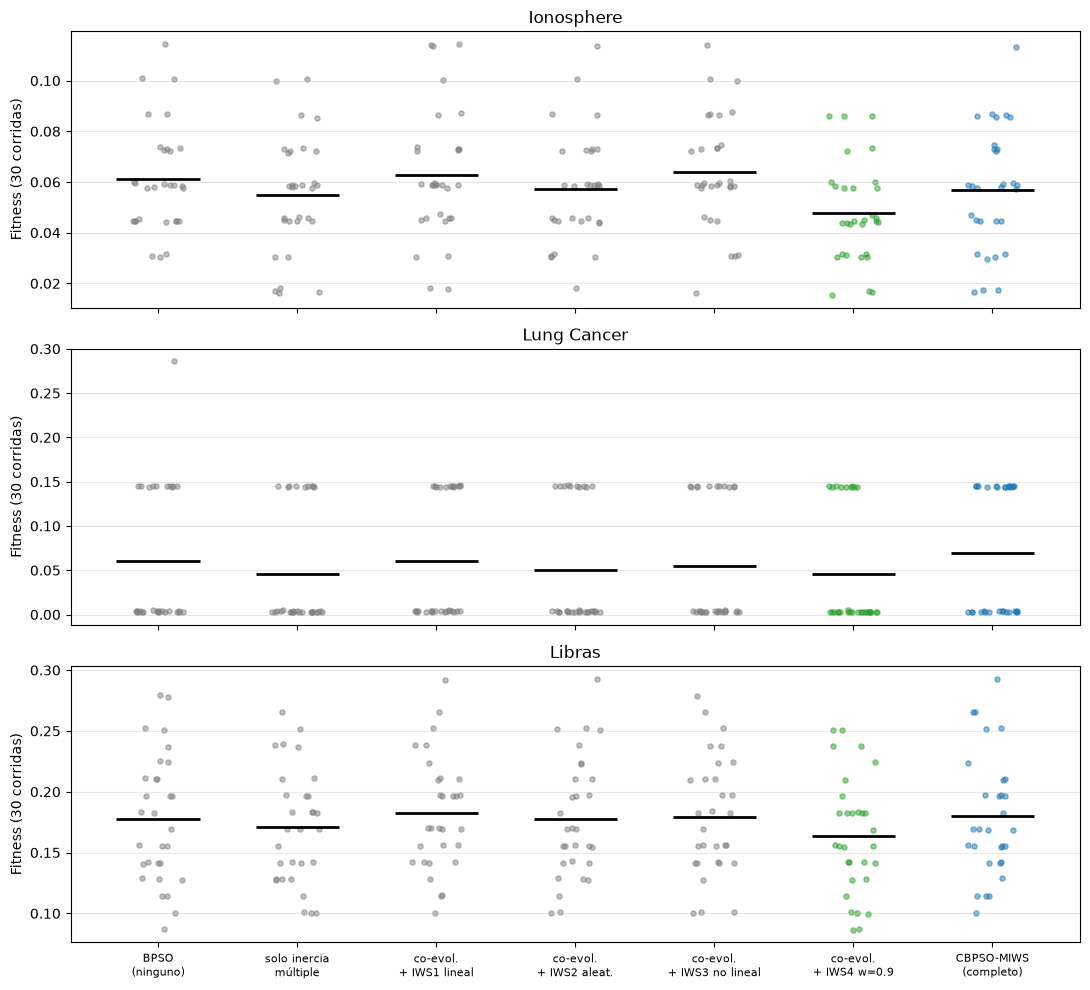

In [10]:
abl = ["bpso", "cbpso_ns1", "cbpso_iws1", "cbpso_iws2", "cbpso_iws3", "cbpso_iws4", "cbpso_miws"]
etq = {"bpso": "BPSO\n(ninguno)", "cbpso_ns1": "solo inercia\nmúltiple", "cbpso_iws1": "co-evol.\n+ IWS1 lineal",
       "cbpso_iws2": "co-evol.\n+ IWS2 aleat.", "cbpso_iws3": "co-evol.\n+ IWS3 no lineal",
       "cbpso_iws4": "co-evol.\n+ IWS4 w=0.9", "cbpso_miws": "CBPSO-MIWS\n(completo)"}
# Puntos = las 30 corridas (con ruido horizontal para que no se encimen); raya negra = media.
# No usamos boxplot: en Lung Cancer la prueba tiene solo 7 pacientes y el fitness toma
# pocos valores discretos, así que las cajas se aplastan y esconden la diferencia.
rng_jit = np.random.default_rng(0)
fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
for ax, base in zip(axes, grandes):
    for i, m in enumerate(abl):
        y = etapa3[(etapa3["dataset"] == base) & (etapa3["method"] == m)]["best_fitness"].to_numpy()
        color = "tab:green" if m == "cbpso_iws4" else "tab:blue" if m == "cbpso_miws" else "gray"
        ax.scatter(i + rng_jit.uniform(-0.18, 0.18, len(y)), y, s=14, alpha=0.5, color=color)
        ax.hlines(y.mean(), i - 0.3, i + 0.3, color="black", lw=2)
    ax.set_title(NOMBRES[base])
    ax.set_ylabel("Fitness (30 corridas)")
    ax.grid(axis="y", alpha=0.3)
axes[-1].set_xticks(range(len(abl)), [etq[m] for m in abl], fontsize=8)
plt.tight_layout()
guardar(fig, "ablacion")
plt.show()

In [11]:
w_abl = compare_all(etapa3, reference="cbpso_miws", challengers=[m for m in abl if m != "cbpso_miws"],
                    metrics=("best_fitness", "accuracy"))
(w_abl[w_abl["metric"] == "best_fitness"]
 .pivot(index="method", columns="dataset", values="resultado_holm").rename(columns=NOMBRES))

dataset,Ionosphere,Libras,Lung Cancer
method,,,
bpso,empate,empate,empate
cbpso_iws1,empate,empate,empate
cbpso_iws2,empate,empate,empate
cbpso_iws3,empate,empate,empate
cbpso_iws4,mejor,mejor,mejor
cbpso_ns1,empate,empate,empate


In [12]:
medias = etapa3[etapa3["method"].isin(abl)].pivot_table(
    index="method", columns="dataset", values=["accuracy", "best_fitness", "n_features"], aggfunc="mean")
medias.loc[abl].round(4)

accuracy                      best_fitness                     n_features                     
dataset    ionosphere   libras lung_cancer   ionosphere  libras lung_cancer ionosphere   libras lung_cancer
method                                                                                                     
bpso          94.1315  82.4537     94.2857       0.0611  0.1779      0.0601    10.1667  37.9333     19.6333
cbpso_ns1     94.7418  83.1481     95.7143       0.0550  0.1711      0.0457    10.0333  38.5000     18.2333
cbpso_iws1    93.9906  82.0370     94.2857       0.0628  0.1823      0.0602    11.1333  40.2667     20.1667
cbpso_iws2    94.5070  82.4537     95.2381       0.0574  0.1779      0.0506    10.2667  38.0000     19.6333
cbpso_iws3    93.8498  82.3148     94.7619       0.0640  0.1793      0.0553    10.7333  38.2667     19.5000
cbpso_iws4    95.4460  83.8889     95.7143       0.0479  0.1634      0.0453     9.4667  35.5000     16.0000
cbpso_miws    94.5540  82.2685     93.3333       0.0568  0.1798      0.0693     9.9667  37.9333     18.6000

**Lectura.**
- Ni la co-evolución sola ni la inercia múltiple sola cambian el resultado de forma significativa
  frente a CBPSO-MIWS completo.
- La configuración con **inercia constante w = 0.9** (IWS 4) es **significativamente mejor** que
  CBPSO-MIWS en fitness en las tres bases y en exactitud en Ionosphere y Libras (Wilcoxon + Holm),
  y además selecciona menos variables (p. ej. Lung Cancer: 95.7 % con 16.0 variables vs. 93.3 % con 18.6).

**¿Por qué?** En PSO binario la inercia funciona al revés que en PSO continuo. La probabilidad de que
un bit valga 1 es S(v) = 1/(1+e^(−v)): con velocidades pequeñas, S(v) ≈ 0.5 y cada bit es un volado.
Los esquemas que **reducen** w a lo largo de la búsqueda (IWS 1 y 3) encogen las velocidades al final y
vuelven aleatoria justo la fase en que el enjambre debería asentarse. Con w = 0.9 constante las velocidades
se mantienen grandes, S(v) se satura cerca de 0 o 1 y la búsqueda **explota** mejor la región encontrada.
Es el mismo diagnóstico que explica por qué la función en V (más exploración) empeora y la búsqueda local
(más explotación) mejora.

## 7. Conclusiones de replicabilidad

| Aspecto | Resultado |
|---|---|
| Exactitud de CBPSO-MIWS vs. artículo | Igual o mayor en 4 de 7 versiones de base (Libras, Ionosphere, Lung Cancer, Glass + ID); menor en Wisconsin, Coimbra y Glass sin ID |
| BPSO vs. artículo | Nuestro BPSO es mejor que el reportado en 5 de 7 versiones de base |
| "CBPSO-MIWS > BPSO" (artículo: 8/10 bases) | **No se replica**: empate en todas las bases (Wilcoxon + Holm) |
| Glass | El artículo casi seguramente usó la columna ID (fuga de etiqueta) |
| Óptimo exacto | CBPSO-MIWS lo halla más seguido que BPSO (~97 % vs. ~77–80 % en Coimbra y Glass) |
| `ns` = 3 o 4 "son mejores" | Sin evidencia: ningún `ns` difiere significativamente |
| Componentes de CBPSO-MIWS | Aportan poco por separado; **w = 0.9 constante** es significativamente mejor (fitness en 3/3 bases, exactitud en 2/3) |

**Dificultades encontradas**
- El artículo no publica código, semillas ni corridas individuales: solo medias, lo que obliga a una prueba de una muestra.
- Detalles omitidos: manejo de faltantes, estratificación de la partición, tamaño de especies cuando N/ns no es entero, uso del ID en Glass.
- El fitness se calcula sobre el mismo 20 % con el que se reporta la exactitud, lo que infla todos los resultados por igual.
- Lung Cancer tiene 32 instancias: el 20 % de prueba son **7 pacientes**, así que la exactitud solo puede moverse en saltos de 14.3 puntos y la varianza entre corridas es enorme (desv. ≈ 7 %).
- Los empates de distancia en KNN (variables enteras en Wisconsin y Coimbra) pueden hacer que el mismo código dé números ligeramente distintos en distintos procesadores; en nuestras dos Mac coincidieron.